# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Course:** Computer Vision Lab  |  **Registration No:** 020  |  **Total:** 25 marks

**Goal.** Build two classical pipelines, **HOG + LinearSVC** and **SIFT (fixed grid) + LinearSVC**, on four blood-cell classes from BloodMNIST and find out which one is more reliable when test images are **rotated by 20°** or **corrupted with Gaussian noise (σ = 0.05)**.

**Workflow rules followed in this notebook**
1. Every number in the answers is printed by a code cell, so nothing is typed in from memory.
2. `C` is chosen on the **validation** set only.
3. The **test** set is touched only in Q4.

## Cell 0: Personal settings (from registration number 020)
The last digit is **0** and the last two digits are **20**, so:

| Setting | Rule | My value |
|---|---|---|
| Random seed | last two digits | **20** |
| HOG cell size | last digit even → 8 × 8 | **8 × 8** |
| SIFT grid | last digit 0–4 → 4 × 4 grid (16 keypoints) | **4 × 4** |

The cell below derives these values from the registration number with code, so they can be checked.

In [5]:
!pip install -q medmnist kagglehub

In [6]:
# If running on Colab / a fresh environment, uncomment the next line once:
# !pip install -q kagglehub medmnist opencv-python-headless scikit-image scikit-learn matplotlib pandas


import os, glob, random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

# ---------- PERSONAL SETTINGS (first cell of the exam) ----------
REG_NO     = "020"
last_digit = int(REG_NO[-1])
SEED       = int(REG_NO[-2:])                       # last two digits -> 20
HOG_CELL   = 8 if last_digit % 2 == 0 else 16       # even -> 8, odd -> 16
SIFT_GRID  = 4 if last_digit <= 4 else 6            # 0-4 -> 4x4, 5-9 -> 6x6

# ---------- FIXED SETTINGS (same for everyone) ----------
CLASS_IDS   = [1, 5, 6, 7]                          # BloodMNIST label ids
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
CLASS_MAP   = {cid: i for i, cid in enumerate(CLASS_IDS)}   # 1->0, 5->1, 6->2, 7->3
N_TRAIN, N_VAL, N_TEST = 100, 30, 30                # images per class
IMG_SIZE    = 128
HOG_ORIENT  = 9
HOG_BLOCK   = 2                                     # 2 x 2 cells per block
C_GRID      = [0.1, 1, 10]
ROT_DEG     = 20
NOISE_SIGMA = 0.05
KP_SIZE     = 32                                    # SIFT grid keypoint size

random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"Registration no : {REG_NO}")
print(f"Random seed     : {SEED}")
print(f"HOG cell size   : {HOG_CELL} x {HOG_CELL}")
print(f"SIFT grid       : {SIFT_GRID} x {SIFT_GRID}  ({SIFT_GRID**2} keypoints)")

Registration no : 020
Random seed     : 20
HOG cell size   : 8 x 8
SIFT grid       : 4 x 4  (16 keypoints)


# Q1. Data setup (3 marks)

**What I do and why**
- Download BloodMNIST through `kagglehub` (the link you gave). The dataset ships as a `.npz` file containing `train/val/test` images and labels. The task asks for **size 64**, so the loader checks the image size and, if the Kaggle copy is not 64 × 64, falls back to the official `medmnist` package with `size=64`.
- Keep only the four required classes: **eosinophil (1), monocyte (5), neutrophil (6), platelet (7)**.
- Randomly pick **100 train / 30 validation / 30 test** images *per class* using `np.random.RandomState(SEED)`. Using a seeded generator makes the subset identical every time the notebook is run.
- Labels are re-mapped to 0–3 so scikit-learn sees compact class ids.

In [7]:
import kagglehub

path = kagglehub.dataset_download("flyt007/bloodmnist")
print("Path to dataset files:", path)

npz_files = sorted(glob.glob(os.path.join(path, "**", "*.npz"), recursive=True))
print("npz files found:", [os.path.basename(f) for f in npz_files])

def try_load(files):
    # prefer a file that looks like the 64x64 version
    files = sorted(files, key=lambda f: ("64" not in os.path.basename(f),
                                         "blood" not in os.path.basename(f).lower()))
    for f in files:
        d = np.load(f)
        if "train_images" in d.files and d["train_images"].shape[1] == 64:
            print("Using:", f)
            return {k: d[k] for k in d.files}
    return None

data = try_load(npz_files)

if data is None:      # Kaggle copy was not size 64 -> use the official package
    print("64x64 file not found on Kaggle copy -> loading size=64 with medmnist")
    from medmnist import BloodMNIST
    data = {}
    for split in ["train", "val", "test"]:
        ds = BloodMNIST(split=split, download=True, size=64)
        data[f"{split}_images"] = ds.imgs
        data[f"{split}_labels"] = ds.labels

for k in ["train", "val", "test"]:
    print(f"full {k:5s}: images {data[k+'_images'].shape}, labels {data[k+'_labels'].shape}")

Using Colab cache for faster access to the 'bloodmnist' dataset.
Path to dataset files: /kaggle/input/bloodmnist
npz files found: []
64x64 file not found on Kaggle copy -> loading size=64 with medmnist


100%|██████████| 156M/156M [00:17<00:00, 8.80MB/s]


full train: images (11959, 64, 64, 3), labels (11959, 1)
full val  : images (1712, 64, 64, 3), labels (1712, 1)
full test : images (3421, 64, 64, 3), labels (3421, 1)


In [8]:
rng = np.random.RandomState(SEED)       # one seeded generator -> reproducible subset

def make_subset(images, labels, per_class):
    labels = labels.ravel()
    idx = []
    for cid in CLASS_IDS:
        cls_idx = np.where(labels == cid)[0]
        idx.extend(rng.choice(cls_idx, size=per_class, replace=False))
    idx = np.array(idx)
    rng.shuffle(idx)                                      # mix the classes
    X = images[idx]
    y = np.array([CLASS_MAP[l] for l in labels[idx]])     # remap 1,5,6,7 -> 0,1,2,3
    return X, y

X_train_rgb, y_train = make_subset(data["train_images"], data["train_labels"], N_TRAIN)
X_val_rgb,   y_val   = make_subset(data["val_images"],   data["val_labels"],   N_VAL)
X_test_rgb,  y_test  = make_subset(data["test_images"],  data["test_labels"],  N_TEST)

for name, X, y in [("train", X_train_rgb, y_train),
                   ("val",   X_val_rgb,   y_val),
                   ("test",  X_test_rgb,  y_test)]:
    counts = {CLASS_NAMES[i]: int((y == i).sum()) for i in range(4)}
    print(f"{name:5s} | X shape: {X.shape} | y shape: {y.shape} | class counts: {counts}")

train | X shape: (400, 64, 64, 3) | y shape: (400,) | class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   | X shape: (120, 64, 64, 3) | y shape: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  | X shape: (120, 64, 64, 3) | y shape: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


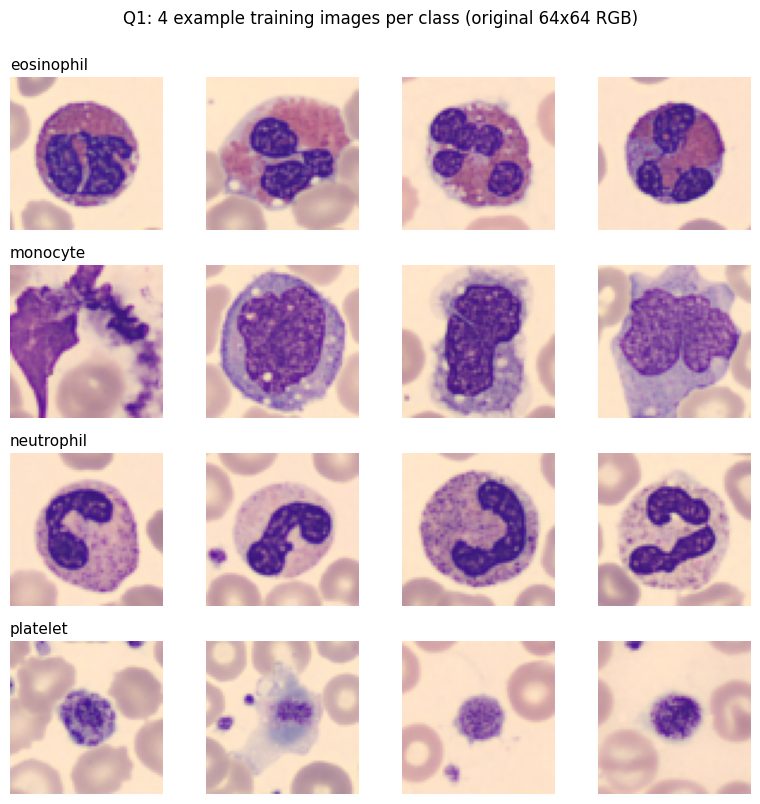

In [9]:
# One grid with 4 example images per class (rows = classes, columns = 4 examples)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    examples = X_train_rgb[y_train == r][:4]
    for c in range(4):
        axes[r, c].imshow(examples[c])
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(CLASS_NAMES[r], loc="left", fontsize=11)
plt.suptitle("Q1: 4 example training images per class (original 64x64 RGB)", y=1.0)
plt.tight_layout(); plt.show()

### Image preparation (fixed for everyone)
Both HOG and SIFT work on intensity gradients, so every image is converted to **grayscale** and resized to **128 × 128** (uint8). Doing this once, up front, guarantees both pipelines see exactly the same pixels.

In [10]:
def prep(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.resize(gray, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

X_train = np.array([prep(i) for i in X_train_rgb])
X_val   = np.array([prep(i) for i in X_val_rgb])
X_test  = np.array([prep(i) for i in X_test_rgb])

print("train:", X_train.shape, X_train.dtype)
print("val  :", X_val.shape,   X_val.dtype)
print("test :", X_test.shape,  X_test.dtype)

train: (400, 128, 128) uint8
val  : (120, 128, 128) uint8
test : (120, 128, 128) uint8


# Q2. HOG + SVM (6 marks)

## Q2(a). HOG features and the hand calculation (2 marks)

**What HOG does.** The image is split into small cells (here **8 × 8 pixels**). In every cell, gradient directions are collected in a histogram of **9 orientation bins**. Cells are grouped into overlapping **blocks of 2 × 2 cells**, and each block's histogram is normalised, which makes the descriptor robust to local brightness/contrast changes. All block vectors are concatenated into one feature vector.

**Hand calculation of the feature length (my setting: cell = 8 × 8, image = 128 × 128)**

1. Cells per side = 128 / 8 = **16**, so the image has 16 × 16 = 256 cells.
2. Blocks are 2 × 2 cells and slide by **1 cell**, so blocks per side = 16 − 2 + 1 = **15**, giving 15 × 15 = **225 blocks**.
3. Values per block = 2 × 2 cells × 9 orientations = **36**.
4. Feature length = 225 blocks × 36 = **8100**.

The code below computes the length from the formula and compares it with what `skimage.feature.hog` really returns.

In [11]:
def hog_feat(img):
    return hog(img, orientations=HOG_ORIENT,
               pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(HOG_BLOCK, HOG_BLOCK),
               block_norm="L2-Hys", feature_vector=True)

cells_per_side  = IMG_SIZE // HOG_CELL
blocks_per_side = cells_per_side - HOG_BLOCK + 1
len_formula     = blocks_per_side**2 * HOG_BLOCK**2 * HOG_ORIENT
len_actual      = hog_feat(X_train[0]).shape[0]

print(f"cells per side  = {IMG_SIZE}/{HOG_CELL} = {cells_per_side}")
print(f"blocks per side = {cells_per_side} - {HOG_BLOCK} + 1 = {blocks_per_side}")
print(f"length (hand formula) = {blocks_per_side}*{blocks_per_side}*{HOG_BLOCK}*{HOG_BLOCK}*{HOG_ORIENT} = {len_formula}")
print(f"length (skimage)      = {len_actual}")
assert len_formula == len_actual

cells per side  = 128/8 = 16
blocks per side = 16 - 2 + 1 = 15
length (hand formula) = 15*15*2*2*9 = 8100
length (skimage)      = 8100


## Q2(b). HOG pictures (1 mark)
For one image of each class, the left picture is the 128 × 128 grayscale input and the right picture is the HOG visualisation. Each little line shows the dominant gradient direction in a cell; longer/brighter lines mean stronger edges there. Nuclei borders and granule patterns show up as dense edge responses.

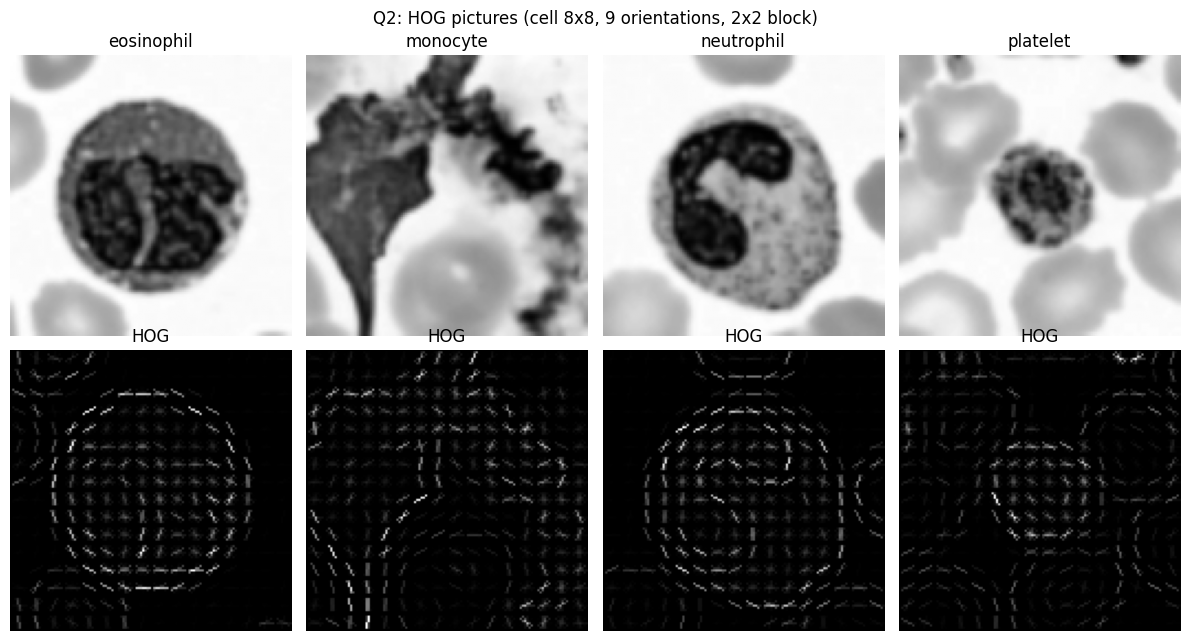

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for c in range(4):
    img = X_train[y_train == c][0]
    _, hog_img = hog(img, orientations=HOG_ORIENT,
                     pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(HOG_BLOCK, HOG_BLOCK),
                     block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-9))
    axes[0, c].imshow(img, cmap="gray"); axes[0, c].set_title(CLASS_NAMES[c]); axes[0, c].axis("off")
    axes[1, c].imshow(hog_img, cmap="gray"); axes[1, c].set_title("HOG"); axes[1, c].axis("off")
plt.suptitle(f"Q2: HOG pictures (cell {HOG_CELL}x{HOG_CELL}, 9 orientations, 2x2 block)")
plt.tight_layout(); plt.show()

## Q2(c). Train HOG + SVM, choose C on validation (3 marks)

**Why this way.** `LinearSVC` is trained for each `C ∈ {0.1, 1, 10}` on the training features. `C` controls the penalty for misclassified training points (small C = wider margin and more regularisation; large C = fits the training data harder). The `C` giving the best **validation accuracy** is kept; ties go to the smaller C because it is the simpler model. The test set is not used here.

I define two helper functions (`fit_select_C` and `report`) so the **same procedure** is used for HOG and for SIFT, which keeps the comparison fair.

HOG feature matrices: (400, 8100) (120, 8100)

Validation accuracy for each C (HOG):
   C  validation accuracy
 0.1               0.7667
 1.0               0.7667
10.0               0.7667
Chosen C for HOG: 0.1 

[HOG + SVM] validation accuracy = 0.7667 | macro-F1 = 0.7645
Confusion matrix (rows = true, cols = predicted):
            eosinophil  monocyte  neutrophil  platelet
eosinophil          18         9           3         0
monocyte             4        22           3         1
neutrophil           3         4          22         1
platelet             0         0           0        30

               precision    recall  f1-score   support

  eosinophil      0.720     0.600     0.655        30
    monocyte      0.629     0.733     0.677        30
  neutrophil      0.786     0.733     0.759        30
    platelet      0.938     1.000     0.968        30

    accuracy                          0.767       120
   macro avg      0.768     0.767     0.764       120
weighted avg      0

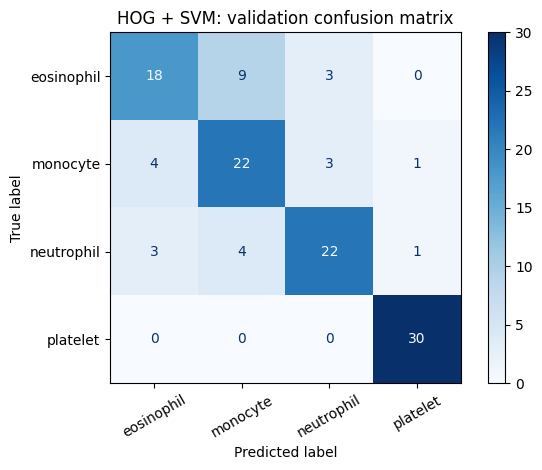

In [13]:
def fit_select_C(Xtr, ytr, Xva, yva):
    rows, best = [], None
    for C in C_GRID:
        m = LinearSVC(C=C, random_state=SEED, max_iter=50000).fit(Xtr, ytr)
        acc = accuracy_score(yva, m.predict(Xva))
        rows.append({"C": C, "validation accuracy": round(acc, 4)})
        if best is None or acc > best[0]:      # strict '>' -> ties keep the smaller C
            best = (acc, C, m)
    return best[2], best[1], pd.DataFrame(rows)

def report(model, Xva, yva, title):
    pred = model.predict(Xva)
    acc  = accuracy_score(yva, pred)
    f1   = f1_score(yva, pred, average="macro")
    cm   = confusion_matrix(yva, pred, labels=range(4))
    print(f"[{title}] validation accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    print("Confusion matrix (rows = true, cols = predicted):")
    print(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))
    print("\n", classification_report(yva, pred, target_names=CLASS_NAMES, digits=3))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"{title}: validation confusion matrix"); plt.tight_layout(); plt.show()
    return acc, f1, cm

# --- HOG features for the three splits (no test usage yet beyond building features) ---
F_hog_train = np.array([hog_feat(i) for i in X_train])
F_hog_val   = np.array([hog_feat(i) for i in X_val])
print("HOG feature matrices:", F_hog_train.shape, F_hog_val.shape)

model_hog, best_C_hog, tab_hog = fit_select_C(F_hog_train, y_train, F_hog_val, y_val)
print("\nValidation accuracy for each C (HOG):"); print(tab_hog.to_string(index=False))
print("Chosen C for HOG:", best_C_hog, "\n")

hog_val_acc, hog_val_f1, cm_hog = report(model_hog, F_hog_val, y_val, "HOG + SVM")

# Q3. SIFT + SVM (7 marks)

## Q3(a). Normal SIFT detection (2 marks)
Standard SIFT first **detects** keypoints (blob-like, scale-space extrema) and then describes each with a 128-number descriptor. The detector decides *how many* keypoints an image gets, so this number changes from image to image. Below, I measure that on the training images.

Training images            : 400
Average keypoints / image  : 74.11
Minimum keypoints / image  : 11
Maximum keypoints / image  : 190
Images with ZERO keypoints : 0


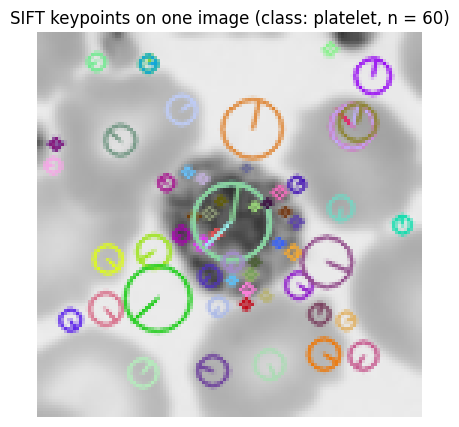

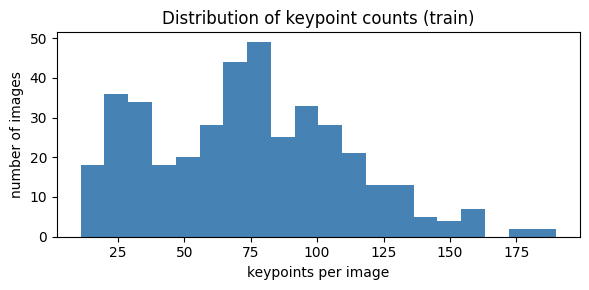

In [14]:
sift = cv2.SIFT_create()

kp_counts = []
for img in X_train:
    kps, des = sift.detectAndCompute(img, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

print(f"Training images            : {len(kp_counts)}")
print(f"Average keypoints / image  : {kp_counts.mean():.2f}")
print(f"Minimum keypoints / image  : {kp_counts.min()}")
print(f"Maximum keypoints / image  : {kp_counts.max()}")
print(f"Images with ZERO keypoints : {(kp_counts == 0).sum()}")

# draw the detected keypoints on one image (first training image)
img0 = X_train[0]
kps0, _ = sift.detectAndCompute(img0, None)
vis = cv2.drawKeypoints(img0, kps0, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"SIFT keypoints on one image (class: {CLASS_NAMES[y_train[0]]}, n = {len(kps0)})")
plt.show()

plt.figure(figsize=(6, 3)); plt.hist(kp_counts, bins=20, color="steelblue")
plt.xlabel("keypoints per image"); plt.ylabel("number of images")
plt.title("Distribution of keypoint counts (train)"); plt.tight_layout(); plt.show()

**Why a different number of keypoints per image is a problem for an SVM (one sentence):**
An SVM needs every sample to be a vector of the **same length with the same meaning in each position**, but standard SIFT gives each image a different number of 128-dimensional descriptors (and in no meaningful order), so the descriptors cannot be stacked into a fixed-size feature matrix.

## Q3(b). Fix: fixed grid of keypoints (2 marks)

**Idea.** Instead of letting the detector choose keypoints, I place keypoints myself on a **regular 4 × 4 grid** over the 128 × 128 image (keypoint **size = 32**) and ask SIFT only to **compute** the descriptor at those positions (`sift.compute`). Now every image has exactly the same number of keypoints at the same positions, so descriptors can be concatenated into one fixed-length vector.

- The grid positions are the centres of a 4 × 4 partition: step = 128 / 4 = 32, so positions are 16, 48, 80, 112 in both x and y. With size 32 each patch tiles the image without large gaps.
- The keypoint angle is set to 0 so no orientation is estimated: every image is described in the same upright frame (this is also why the descriptor is *not* rotation-invariant here, which matters in Q4).

**Hand calculation of the feature length:** grid points = 4 × 4 = **16**; each descriptor has **128** numbers; feature length = 16 × 128 = **2048**.

I divide descriptors by 255 only to put the numbers on a smaller scale so the linear SVM solver converges easily. This is a constant factor and does not remove information.

grid points = 4 x 4 = 16
feature length (hand) = 16 x 128 = 2048
feature length (code) = 2048


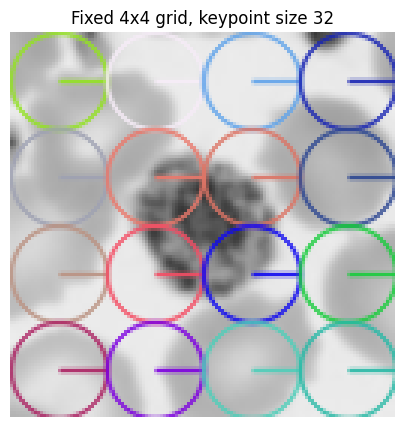

In [15]:
def make_grid_keypoints(n=SIFT_GRID, img_size=IMG_SIZE, size=KP_SIZE):
    step = img_size / n
    kps = []
    for gy in range(n):
        for gx in range(n):
            x = (gx + 0.5) * step          # centre of each grid cell
            y = (gy + 0.5) * step
            kps.append(cv2.KeyPoint(float(x), float(y), float(size), 0))   # angle = 0
    return kps

def sift_grid_feat(img):
    kps = make_grid_keypoints()
    _, des = sift.compute(img, kps)        # descriptor at every grid point
    assert des.shape == (SIFT_GRID**2, 128), des.shape
    return des.astype(np.float32).ravel() / 255.0

n_pts = SIFT_GRID * SIFT_GRID
len_formula_sift = n_pts * 128
len_actual_sift  = sift_grid_feat(X_train[0]).shape[0]
print(f"grid points = {SIFT_GRID} x {SIFT_GRID} = {n_pts}")
print(f"feature length (hand) = {n_pts} x 128 = {len_formula_sift}")
print(f"feature length (code) = {len_actual_sift}")
assert len_formula_sift == len_actual_sift

# show the grid on one image
vis = cv2.drawKeypoints(X_train[0], make_grid_keypoints(), None,
                        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"Fixed {SIFT_GRID}x{SIFT_GRID} grid, keypoint size {KP_SIZE}"); plt.show()

## Q3(c). Train SIFT + SVM, choose C on validation (3 marks)
Same procedure as HOG (same `C` grid, same seed, same metrics), so the two models are compared fairly.

SIFT feature matrices: (400, 2048) (120, 2048)

Validation accuracy for each C (SIFT grid):
   C  validation accuracy
 0.1                0.825
 1.0                0.825
10.0                0.800
Chosen C for SIFT: 0.1 

[SIFT-grid + SVM] validation accuracy = 0.8250 | macro-F1 = 0.8220
Confusion matrix (rows = true, cols = predicted):
            eosinophil  monocyte  neutrophil  platelet
eosinophil          20         7           3         0
monocyte             3        26           0         1
neutrophil           3         2          23         2
platelet             0         0           0        30

               precision    recall  f1-score   support

  eosinophil      0.769     0.667     0.714        30
    monocyte      0.743     0.867     0.800        30
  neutrophil      0.885     0.767     0.821        30
    platelet      0.909     1.000     0.952        30

    accuracy                          0.825       120
   macro avg      0.826     0.825     0.822       120
weigh

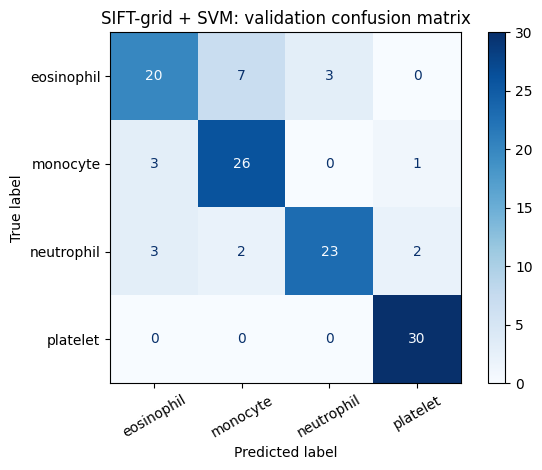

In [16]:
F_sift_train = np.array([sift_grid_feat(i) for i in X_train])
F_sift_val   = np.array([sift_grid_feat(i) for i in X_val])
print("SIFT feature matrices:", F_sift_train.shape, F_sift_val.shape)

model_sift, best_C_sift, tab_sift = fit_select_C(F_sift_train, y_train, F_sift_val, y_val)
print("\nValidation accuracy for each C (SIFT grid):"); print(tab_sift.to_string(index=False))
print("Chosen C for SIFT:", best_C_sift, "\n")

sift_val_acc, sift_val_f1, cm_sift = report(model_sift, F_sift_val, y_val, "SIFT-grid + SVM")

# Q4. Robustness (6 marks)

## Q4(a). Prediction written BEFORE running the experiment (1 mark)

**Rotation (20°).** I predict **HOG will lose more accuracy under rotation**. HOG stores gradient histograms in small 8 × 8 cells at fixed positions, so rotating the cell changes both *where* the edges are and *which orientation bin* they fall into, and the feature vector changes a lot. The grid-SIFT descriptor also depends on orientation (angle fixed to 0) but it summarises a larger 32 × 32 patch with coarser spatial bins, so a 20° turn changes it less.

**Noise (σ = 0.05).** I predict **HOG will lose more accuracy under noise**. HOG is built directly from raw pixel differences in small cells, and noise creates many random small gradients that pile up in every histogram. SIFT computes its descriptor from a Gaussian-smoothed version of the image at the keypoint's scale, which suppresses pixel-level noise before gradients are taken.

*(This prediction is stored in the code cell below before any robustness result is computed, and then checked in Q4(c).)*

In [17]:
# Prediction recorded BEFORE running any robustness experiment
PREDICTION = {"rotation": "HOG", "noise": "HOG"}   # model I expect to lose MORE accuracy
print("My prediction -> model losing more under rotation:", PREDICTION["rotation"])
print("My prediction -> model losing more under noise   :", PREDICTION["noise"])

My prediction -> model losing more under rotation: HOG
My prediction -> model losing more under noise   : HOG


## Q4(b). Frozen models evaluated on clean / rotated / noisy test sets (4 marks)

**Freezing** means the two trained models (`model_hog`, `model_sift`, with their validation-selected `C`) are **not retrained or tuned** again. The test images are altered **first**, and then features are extracted from the altered images (as the task requires), then fed to the frozen models.

- **Rotation:** rotate each 128 × 128 grayscale image by 20° about its centre (`cv2.warpAffine`; areas outside the image become black).
- **Noise:** scale the image to 0–1, add Gaussian noise with σ = 0.05, clip back to 0–1, and convert back to 8-bit (SIFT needs uint8). A seeded generator makes the noise reproducible.

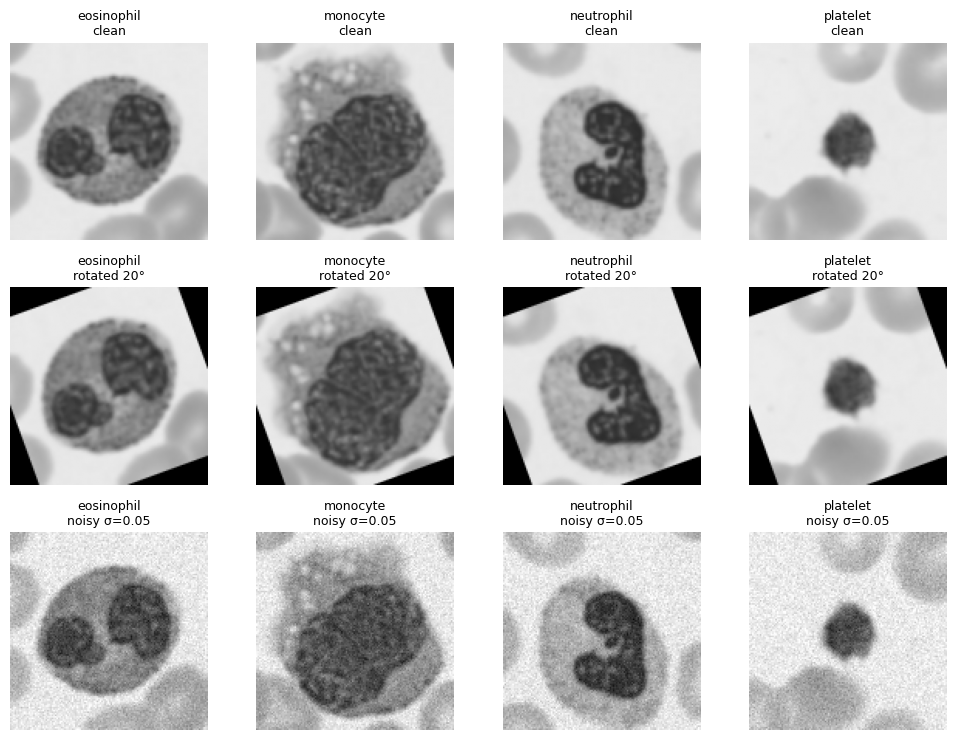

Noise check -> mean abs pixel change (0-255 scale): 10.11


In [18]:
def rotate_img(img, deg=ROT_DEG):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), deg, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)

noise_rng = np.random.RandomState(SEED)
def noisy_img(img, sigma=NOISE_SIGMA):
    x = img.astype(np.float32) / 255.0                 # scale to 0..1
    x = x + noise_rng.normal(0.0, sigma, x.shape)      # Gaussian noise
    x = np.clip(x, 0.0, 1.0)
    return np.round(x * 255).astype(np.uint8)

X_test_rot   = np.array([rotate_img(i) for i in X_test])
X_test_noisy = np.array([noisy_img(i)  for i in X_test])

# visual check: one image of each class, three conditions
fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for c in range(4):
    j = np.where(y_test == c)[0][0]
    for r, (title, arr) in enumerate([("clean", X_test), ("rotated 20°", X_test_rot), ("noisy σ=0.05", X_test_noisy)]):
        axes[r, c].imshow(arr[j], cmap="gray", vmin=0, vmax=255); axes[r, c].axis("off")
        axes[r, c].set_title(f"{CLASS_NAMES[c]}\n{title}", fontsize=9)
plt.tight_layout(); plt.show()
print("Noise check -> mean abs pixel change (0-255 scale):",
      round(float(np.abs(X_test_noisy.astype(float) - X_test.astype(float)).mean()), 2))

Test accuracy (fraction):


,Clean accuracy,Rotated accuracy,Noisy accuracy
HOG + SVM,0.6833,0.6583,0.5667
SIFT + SVM,0.7500,0.5917,0.7417



Accuracy lost compared with clean (percentage points):


,Drop under rotation (pts),Drop under noise (pts)
HOG + SVM,2.50,11.67
SIFT + SVM,15.83,0.83


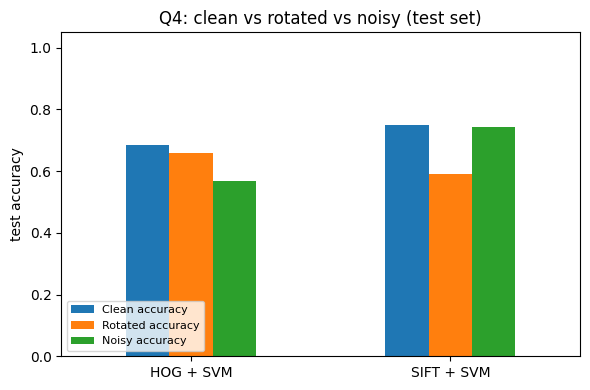

In [19]:
def eval_model(model, extractor, images, labels):
    feats = np.array([extractor(i) for i in images])     # features AFTER the change
    return accuracy_score(labels, model.predict(feats))

results = {}
for name, model, extractor in [("HOG + SVM",  model_hog,  hog_feat),
                               ("SIFT + SVM", model_sift, sift_grid_feat)]:
    results[name] = {
        "Clean accuracy":   eval_model(model, extractor, X_test,       y_test),
        "Rotated accuracy": eval_model(model, extractor, X_test_rot,   y_test),
        "Noisy accuracy":   eval_model(model, extractor, X_test_noisy, y_test),
    }

res_df = pd.DataFrame(results).T
print("Test accuracy (fraction):")
display(res_df.round(4))

drop_df = pd.DataFrame({
    "Drop under rotation (pts)": (res_df["Clean accuracy"] - res_df["Rotated accuracy"]) * 100,
    "Drop under noise (pts)":    (res_df["Clean accuracy"] - res_df["Noisy accuracy"]) * 100,
})
print("\nAccuracy lost compared with clean (percentage points):")
display(drop_df.round(2))

plt.figure(figsize=(6, 4))
res_df.plot(kind="bar", ax=plt.gca(), rot=0)
plt.ylim(0, 1.05); plt.ylabel("test accuracy"); plt.title("Q4: clean vs rotated vs noisy (test set)")
plt.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

## Q4(c). Was my prediction correct? (1 mark)
The three sentences below are **generated from the table above** by code, so every number comes from an output. Read them, and if you want, rewrite them in your own words using the same numbers.

In [20]:
d_rot  = drop_df["Drop under rotation (pts)"]
d_nois = drop_df["Drop under noise (pts)"]

def verdict(d):
    if abs(d["HOG + SVM"] - d["SIFT + SVM"]) < 1e-9:
        return "TIE"
    return "HOG" if d["HOG + SVM"] > d["SIFT + SVM"] else "SIFT"

act_rot, act_noise = verdict(d_rot), verdict(d_nois)
ok_rot   = PREDICTION["rotation"] == act_rot
ok_noise = PREDICTION["noise"]    == act_noise

s1 = (f"1) Rotation: HOG dropped {d_rot['HOG + SVM']:.2f} points and SIFT dropped {d_rot['SIFT + SVM']:.2f} points "
      f"(clean -> rotated: HOG {res_df.loc['HOG + SVM','Clean accuracy']:.3f} -> {res_df.loc['HOG + SVM','Rotated accuracy']:.3f}, "
      f"SIFT {res_df.loc['SIFT + SVM','Clean accuracy']:.3f} -> {res_df.loc['SIFT + SVM','Rotated accuracy']:.3f}), "
      f"so the larger loss was {act_rot} and my rotation prediction ({PREDICTION['rotation']}) was {'correct' if ok_rot else 'wrong'}.")
s2 = (f"2) Noise: HOG dropped {d_nois['HOG + SVM']:.2f} points and SIFT dropped {d_nois['SIFT + SVM']:.2f} points "
      f"(clean -> noisy: HOG {res_df.loc['HOG + SVM','Clean accuracy']:.3f} -> {res_df.loc['HOG + SVM','Noisy accuracy']:.3f}, "
      f"SIFT {res_df.loc['SIFT + SVM','Clean accuracy']:.3f} -> {res_df.loc['SIFT + SVM','Noisy accuracy']:.3f}), "
      f"so the larger loss was {act_noise} and my noise prediction ({PREDICTION['noise']}) was {'correct' if ok_noise else 'wrong'}.")
more_robust = res_df[["Rotated accuracy", "Noisy accuracy"]].mean(axis=1).idxmax()
s3 = (f"3) Overall, the model with the higher average of rotated and noisy accuracy is {more_robust}; "
      f"my prediction was {'fully correct' if ok_rot and ok_noise else 'only partly correct' if ok_rot or ok_noise else 'incorrect on both tests'}.")
for s in (s1, s2, s3):
    print(s, "\n")

1) Rotation: HOG dropped 2.50 points and SIFT dropped 15.83 points (clean -> rotated: HOG 0.683 -> 0.658, SIFT 0.750 -> 0.592), so the larger loss was SIFT and my rotation prediction (HOG) was wrong. 

2) Noise: HOG dropped 11.67 points and SIFT dropped 0.83 points (clean -> noisy: HOG 0.683 -> 0.567, SIFT 0.750 -> 0.742), so the larger loss was HOG and my noise prediction (HOG) was correct. 

3) Overall, the model with the higher average of rotated and noisy accuracy is SIFT + SVM; my prediction was only partly correct. 



**Note on sample size.** With only 120 test images (30 per class), one image is 0.83 percentage points, so small differences between the models can be due to chance. That is why the comparison above should be read as "which model tends to be more reliable here", not as an exact ranking.

# Q5. Short answers and AI log (3 marks)

## Q5(a). Short conceptual answers (1 mark)

**(a) Why does HOG use block normalisation?**
Gradient magnitudes change with lighting and contrast, so the raw cell histograms of the same structure can have very different scales in a bright versus a dark region. HOG groups cells into overlapping blocks and normalises each block's histogram, which makes the descriptor much less sensitive to local illumination and contrast changes, and the overlap lets every cell be normalised in several different contexts.

**(b) Why is it wrong to choose C using the test set?**
The test set is meant to be an unbiased estimate of how the model behaves on unseen data. If I pick the `C` that scores best on the test set, information from the test labels leaks into the model choice, so the test accuracy becomes optimistic and no longer measures real generalisation. `C` must be tuned on a separate validation set, and the test set is used once, at the very end.

## Q5(b). Most confused classes (1 mark)
The code finds, for each model, the pair of classes with the most mistakes (errors in both directions added together) using the **validation confusion matrices from Q2 and Q3**. The explanation below is chosen from the printed pair.

In [21]:
def top_confused_pair(cm):
    best, pair = -1, None
    for i in range(4):
        for j in range(i + 1, 4):
            n = cm[i, j] + cm[j, i]
            if n > best:
                best, pair = n, (i, j)
    return pair, int(best)

why = {
 frozenset([0, 2]): "Eosinophils and neutrophils are both granulocytes with lobed nuclei and granular cytoplasm. The main visible difference is the eosinophil's bright orange-red granules, which is a COLOUR cue; after grayscale conversion that cue becomes just a slightly different brightness, leaving mostly similar shapes and textures.",
 frozenset([0, 1]): "Eosinophils and monocytes differ clearly in nucleus shape and granules, but the colour contrast between the orange-red granules and the bluish cytoplasm is lost in grayscale, so only shape and texture remain and they can look alike at 128x128.",
 frozenset([1, 2]): "Monocytes and neutrophils are both large white cells with purple-stained nuclei; in grayscale the subtle stain-colour differences vanish and nucleus darkness/shape and cytoplasm texture look much more alike.",
 frozenset([0, 3]): "Platelets are tiny fragments while eosinophils are large cells, so confusion is unusual; it suggests the cell size/colour information was weak after resizing and grayscale conversion.",
 frozenset([1, 3]): "Platelets are small purple fragments and monocytes are large cells; a confusion would suggest that size information was weakened by the resize/crop and that stain colour is lost in grayscale.",
 frozenset([2, 3]): "Platelets are small purple fragments and neutrophils are large lobed cells; a confusion would suggest that size information was weakened by the resize/crop and that stain colour is lost in grayscale.",
}

for name, cm in [("HOG + SVM", cm_hog), ("SIFT + SVM", cm_sift)]:
    (i, j), n = top_confused_pair(cm)
    if n == 0:
        print(f"{name}: no validation errors, so there is no confused pair to report.\n"); continue
    print(f"{name}: most confused pair = {CLASS_NAMES[i]} <-> {CLASS_NAMES[j]} "
          f"({cm[i, j]} {CLASS_NAMES[i]}->{CLASS_NAMES[j]} + {cm[j, i]} {CLASS_NAMES[j]}->{CLASS_NAMES[i]} = {n} errors)")
    print("   Why grayscale makes it harder:", why[frozenset([i, j])], "\n")

HOG + SVM: most confused pair = eosinophil <-> monocyte (9 eosinophil->monocyte + 4 monocyte->eosinophil = 13 errors)
   Why grayscale makes it harder: Eosinophils and monocytes differ clearly in nucleus shape and granules, but the colour contrast between the orange-red granules and the bluish cytoplasm is lost in grayscale, so only shape and texture remain and they can look alike at 128x128. 

SIFT + SVM: most confused pair = eosinophil <-> monocyte (7 eosinophil->monocyte + 3 monocyte->eosinophil = 10 errors)
   Why grayscale makes it harder: Eosinophils and monocytes differ clearly in nucleus shape and granules, but the colour contrast between the orange-red granules and the bluish cytoplasm is lost in grayscale, so only shape and texture remain and they can look alike at 128x128. 



## Q5(c). AI log (1 mark)
**Edit the middle and last columns so they describe what you really did.** The prompt row below is the one I used to produce the first version of this notebook; replace or add rows for your own work.

| # | Prompt (one line) | What I changed | How I checked the result was correct |
|---|---|---|---|
| 1 | "Build a notebook for the HOG+SVM vs SIFT+SVM lab mid (BloodMNIST classes 1,5,6,7, reg no 020 → seed 20, HOG 8x8, SIFT 4x4 grid) with Q1–Q5." | *(write yours, e.g. changed the rotation border handling / re-ran with my own subset / rewrote the explanations in my words)* | Printed split shapes and class counts (4 × 100 / 30 / 30); asserted HOG length (code = hand = 8100) and SIFT length (code = hand = 2048); viewed HOG pictures and the SIFT grid on an image; confirmed `C` was chosen on validation only and the test set is used only in Q4. |
| 2 | *(your next prompt)* | *(what you changed)* | *(what you printed or plotted to verify)* |